# Calibracao das probabilidades preditas pelos cinco algoritmos

Este notebook avalia a calibracao das probabilidades de obito preditas pelos cinco algoritmos sobre o teste de 2024, alem da capacidade de ordenacao e discriminacao ja avaliada nos notebooks anteriores desta fase.
Um modelo bem calibrado produz probabilidades que correspondem, na media, a frequencia observada de obito entre os casos com aquela probabilidade predita, o que e essencial se as probabilidades forem usadas diretamente para apoiar decisao clinica, e nao apenas para ordenar os casos por risco.
A calibracao e avaliada de duas formas complementares: pelo Brier Skill Score, que resume a qualidade das probabilidades num unico numero relativo a um modelo de referencia, e por curvas de calibracao, que mostram visualmente se as probabilidades preditas estao sistematicamente acima ou abaixo da frequencia observada ao longo da faixa de risco.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria os diretorios de saida usados ao longo do notebook.
A tabela de calibracao por decil e salva em `analysis/results_avaliacao/`, e os graficos de curvas de calibracao sao salvos em `analysis/plots/avaliacao/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "cart", "random_forest", "xgboost", "lightgbm"]
NUMERO_DECIS = 10

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real salvos pela fase de modelagem para o teste de 2024, e calcula a prevalencia observada de obito nesse conjunto.
Essa prevalencia e usada na secao seguinte como a probabilidade constante do modelo de referencia do Brier Skill Score.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
prevalencia_obito_teste2024 = alvo_real_teste2024.mean()

prevalencia_obito_teste2024

np.float64(0.05228758169934641)

Calcula o Brier Score do modelo de referencia, que sempre prediz a prevalencia observada de obito para todos os casos, e o Brier Score de cada um dos cinco algoritmos, usando `avaliar_predicoes` de `utils/preprocessamento.py`.
O Brier Skill Score de cada algoritmo e definido como `1 - brier_modelo / brier_referencia`, de forma que um BSS positivo indica que o algoritmo produz probabilidades mais proximas da frequencia observada do que a referencia ingenua, um BSS igual a zero indica desempenho equivalente ao da referencia, e um BSS negativo indica que o algoritmo e pior que simplesmente prever a prevalencia para todos os casos.

In [3]:
probabilidade_referencia = np.full(len(alvo_real_teste2024), prevalencia_obito_teste2024)
brier_referencia = brier_score_loss(alvo_real_teste2024, probabilidade_referencia)

linhas_bss = []
for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    metricas = preprocessamento.avaliar_predicoes(alvo_real_teste2024, probabilidade_predita)
    brier_skill_score = 1 - metricas["brier_score"] / brier_referencia
    linhas_bss.append(
        {
            "algoritmo": algoritmo,
            "brier_score": metricas["brier_score"],
            "brier_score_referencia": brier_referencia,
            "brier_skill_score": brier_skill_score,
        }
    )

tabela_bss = pd.DataFrame(linhas_bss).sort_values("brier_skill_score", ascending=False).reset_index(drop=True)
tabela_bss.to_csv(DIRETORIO_RESULTADOS_ANALISE / "brier_skill_score_teste2024.csv", index=False)
tabela_bss

,algoritmo,brier_score,brier_score_referencia,brier_skill_score
0,random_forest,0.066271,0.049554,-0.337367
1,lightgbm,0.180938,0.049554,-2.651353
2,xgboost,0.181249,0.049554,-2.657637
3,cart,0.207120,0.049554,-3.179715
4,regressao_logistica,0.231823,0.049554,-3.678233


Constroi, para cada algoritmo, a tabela de calibracao por decil de probabilidade predita.
Os casos do teste de 2024 sao divididos em decis pela propria probabilidade predita de cada algoritmo, usando `pd.qcut`, e para cada decil sao calculados o numero de casos, a probabilidade media predita e a fracao observada de obito.
Quando um algoritmo produz poucos valores distintos de probabilidade, como o CART, decis adjacentes podem ter a mesma fronteira e serem automaticamente combinados por `pd.qcut`, o que resulta em menos de dez decis efetivos para esse algoritmo.

In [4]:
tabelas_calibracao_por_decil = []
for algoritmo in ALGORITMOS:
    tabela_algoritmo = predicoes_teste2024[algoritmo].copy()
    tabela_algoritmo["decil"] = pd.qcut(
        tabela_algoritmo["probabilidade_predita"], NUMERO_DECIS, labels=False, duplicates="drop"
    )

    resumo_decis = (
        tabela_algoritmo.groupby("decil")
        .agg(
            numero_casos=("obito", "size"),
            probabilidade_media_predita=("probabilidade_predita", "mean"),
            fracao_observada_obito=("obito", "mean"),
        )
        .reset_index()
    )
    resumo_decis["decil"] = resumo_decis["decil"] + 1
    resumo_decis["algoritmo"] = algoritmo
    resumo_decis["numero_decis_efetivo"] = resumo_decis["decil"].max()

    tabelas_calibracao_por_decil.append(resumo_decis)

tabela_calibracao_por_decil = pd.concat(tabelas_calibracao_por_decil, ignore_index=True)[
    ["algoritmo", "decil", "numero_decis_efetivo", "numero_casos", "probabilidade_media_predita", "fracao_observada_obito"]
]

tabela_calibracao_por_decil.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "calibracao_por_decil.csv", index=False
)
tabela_calibracao_por_decil

,algoritmo,decil,numero_decis_efetivo,numero_casos,probabilidade_media_predita,fracao_observada_obito
0,regressao_logistica,1,10,398,0.160486,0.005025
1,regressao_logistica,2,10,398,0.239113,0.007538
2,regressao_logistica,3,10,398,0.293779,0.015075
3,regressao_logistica,4,10,397,0.348254,0.007557
4,regressao_logistica,5,10,398,0.407326,0.017588
5,regressao_logistica,6,10,398,0.470000,0.027638
6,regressao_logistica,7,10,397,0.535624,0.042821
7,regressao_logistica,8,10,398,0.612756,0.057789
8,regressao_logistica,9,10,398,0.701591,0.120603
9,regressao_logistica,10,10,398,0.824382,0.221106


Gera as curvas de calibracao dos cinco algoritmos num unico grafico, usando `calibration_curve` com decis de probabilidade predita.
A diagonal pontilhada representa a calibracao perfeita, em que a probabilidade predita e igual a fracao observada de obito, e curvas acima dessa diagonal indicam subestimacao do risco, enquanto curvas abaixo indicam sobreestimacao.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_5_algoritmos.png`.

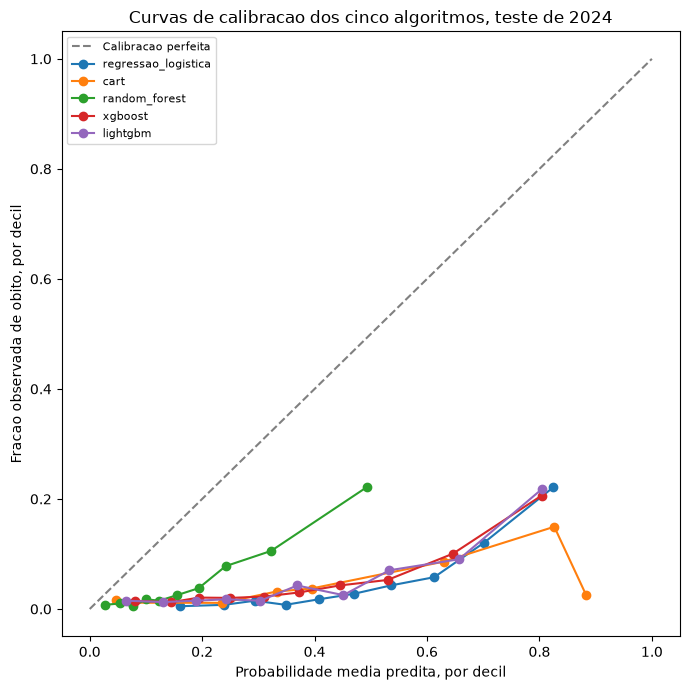

In [5]:
figura, eixo = plt.subplots(figsize=(7, 7))
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibracao perfeita")

for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo.plot(probabilidade_media, fracao_observada, marker="o", label=algoritmo)

eixo.set_xlabel("Probabilidade media predita, por decil")
eixo.set_ylabel("Fracao observada de obito, por decil")
eixo.set_title("Curvas de calibracao dos cinco algoritmos, teste de 2024")
eixo.legend(loc="upper left", fontsize=8)
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_5_algoritmos.png", dpi=150)
plt.show()

Gera o mesmo conjunto de curvas de calibracao em paineis separados por algoritmo, com a mesma escala de eixos para os cinco paineis, o que facilita a leitura individual de cada curva sem a sobreposicao visual do grafico unico anterior.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_por_algoritmo.png`.

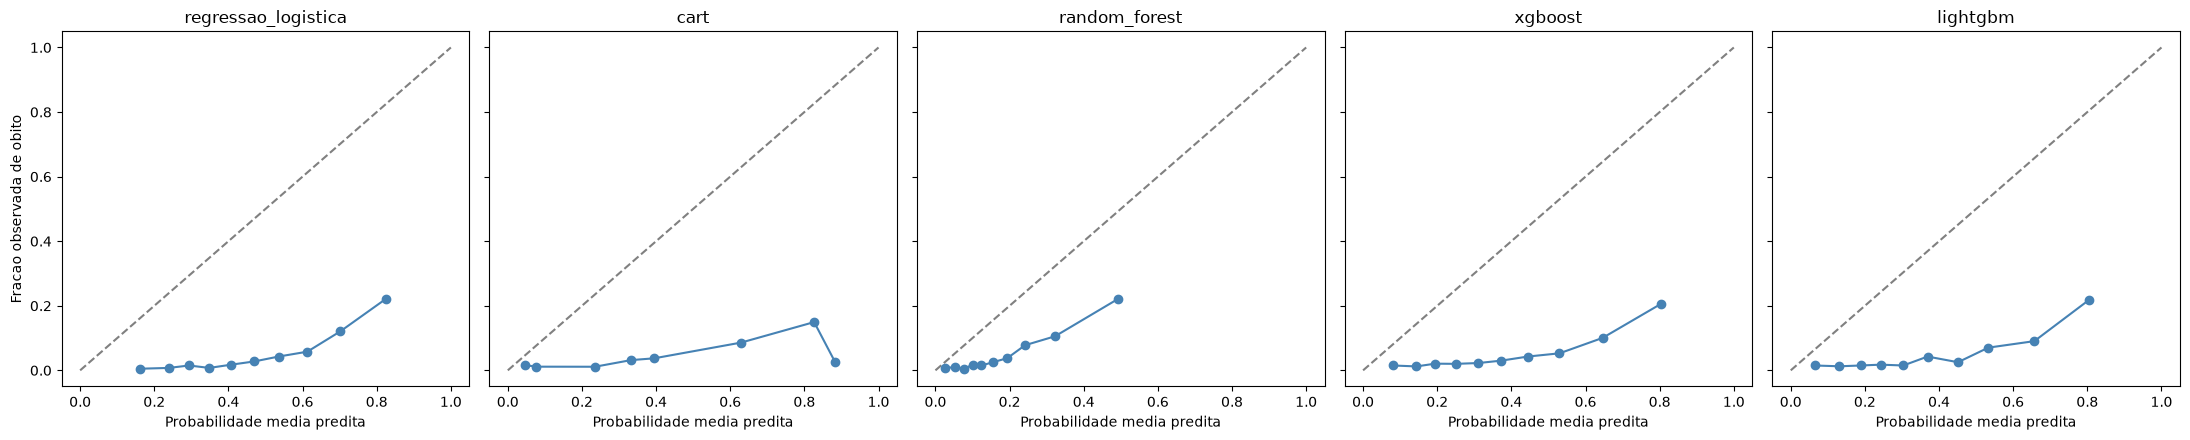

In [6]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(22, 4.5), sharex=True, sharey=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo_atual.plot([0, 1], [0, 1], linestyle="--", color="gray")
    eixo_atual.plot(probabilidade_media, fracao_observada, marker="o", color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Probabilidade media predita")

eixos[0].set_ylabel("Fracao observada de obito")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_por_algoritmo.png", dpi=150)
plt.show()

## Sintese dos achados

O Brier Skill Score dos cinco algoritmos e negativo em todos os casos, de -0,337 para o Random Forest a -3,678 para a Regressao Logistica, o que significa que nenhum dos cinco algoritmos supera, em Brier Score absoluto, o modelo de referencia trivial que sempre prediz a prevalencia observada de obito, 5,23 por cento, para todos os casos.
Essa e uma consequencia direta da baixa prevalencia de obito combinada com o objetivo de discriminar os casos de maior risco, e nao uma falha isolada de um algoritmo especifico.
A referencia trivial ja acerta a maioria das observacoes ao prever um numero pequeno para quase todos os casos, que de fato nao evoluem a obito, enquanto qualquer modelo que atribua probabilidades altas aos casos de maior risco paga um custo em erro quadratico sempre que esse risco elevado nao se concretiza, o que e frequente mesmo nos decis de maior risco, ja que a prevalencia de obito permanece baixa mesmo entre os casos mais graves.
O Random Forest tem o Brier Skill Score menos negativo entre os cinco algoritmos, o que confirma, em termos relativos ao modelo de referencia, a leitura ja indicada pelo Brier Score absoluto na fase de modelagem.
A tabela por decil mostra a razao concreta dessa vantagem relativa: no decil de maior risco, a probabilidade media predita pelo Random Forest e 0,492 contra uma fracao observada de obito de 0,221, uma distancia bem menor do que a da Regressao Logistica, cujo decil de maior risco tem probabilidade media de 0,824 contra a mesma fracao observada de obito de 0,221.
Esse deslocamento acentuado da Regressao Logistica para probabilidades muito acima da frequencia real, visivel em quase todos os decis na curva de calibracao, e consequencia direta do uso de `class_weight="balanced"`, que melhora a discriminacao entre as classes mas piora sistematicamente a correspondencia entre a probabilidade predita e a frequencia real.
XGBoost e LightGBM tem Brier Skill Score muito proximos entre si, -2,658 e -2,651, e padroes de calibracao semelhantes, tambem com probabilidades deslocadas para cima em relacao a diagonal de calibracao perfeita ao longo de quase toda a faixa de risco, embora de forma menos extrema do que a Regressao Logistica.
O CART tem poucos valores distintos de probabilidade predita, o que reduz a oito o numero de decis efetivos nessa analise, e seu ultimo decil mostra uma fracao observada de obito de apenas 0,026 apesar de uma probabilidade media predita de 0,883, a maior distancia entre probabilidade predita e frequencia observada entre todos os algoritmos e decis analisados.
Em conjunto, estes resultados indicam que a boa capacidade de ordenacao de risco dos cinco algoritmos, ja documentada pela AUPRC e pelo ROC-AUC na fase de modelagem, nao se traduz em probabilidades absolutas bem calibradas em relacao a uma referencia ingenua, e que o Random Forest, apesar disso, e o algoritmo cujas probabilidades mais se aproximam da frequencia observada de obito entre os cinco avaliados.